# Task2 : Unemployment Analysis with python

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Libraries imported")


C:\Users\dell\anaconda\anaconda.rr\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Libraries imported


In [3]:
df = pd.read_csv("Unemployment in India.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

df.head(9)

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
5,Andhra Pradesh,31-10-2019,Monthly,3.52,12017412.0,43.01,Rural
6,Andhra Pradesh,30-11-2019,Monthly,4.12,11397681.0,41.00,Rural
7,Andhra Pradesh,31-12-2019,Monthly,4.38,12528395.0,45.14,Rural
8,Andhra Pradesh,31-01-2020,Monthly,4.84,12016676.0,43.46,Rural


In [4]:
print("Dataset shape:")
print(df.shape)

Dataset shape:
(768, 7)


In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


In [6]:
print("Data types:")
print(df.dtypes)

Data types:
Region                                      object
Date                                        object
Frequency                                   object
Estimated Unemployment Rate (%)            float64
Estimated Employed                         float64
Estimated Labour Participation Rate (%)    float64
Area                                        object
dtype: object


In [7]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


In [8]:
# 1. Remove spaces from text columns(using strip)
df.columns = df.columns.str.strip()

# 2. Drop completely empty rows
df.dropna(subset=['Region'], inplace=True)

# 3. Strip whitespace from text fields
for col in ['Region', 'Frequency', 'Area']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

        
# 4. Convert date strings to datetime
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True,
    errors="coerce"
)

# 5. Convert numerical columns
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 6. Remove rows without essential information
df = df.dropna(
    subset=[
        "Region",
        "Date",
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
)

# 7. Sort observations chronologically
df = df.sort_values("Date").reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("Remaining missing values:")
print(df.isnull().sum())   

Cleaned dataset shape: (740, 7)
Remaining missing values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


In [9]:
print(df[['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)']].describe().round())

       Estimated Unemployment Rate (%)  Estimated Employed  \
count                            740.0               740.0   
mean                              12.0           7204460.0   
std                               11.0           8087988.0   
min                                0.0             49420.0   
25%                                5.0           1190404.0   
50%                                8.0           4744178.0   
75%                               16.0          11275490.0   
max                               77.0          45777509.0   

       Estimated Labour Participation Rate (%)  
count                                    740.0  
mean                                      43.0  
std                                        8.0  
min                                       13.0  
25%                                       38.0  
50%                                       41.0  
75%                                       46.0  
max                                       73.0  


In [10]:
unemployment_col = "Estimated Unemployment Rate (%)"

region_average = (
    df.groupby("Region")[unemployment_col]
    .mean()
    .sort_values(ascending=False)
)

print("Average unemployment rate by region:")
display(region_average.to_frame("Average Unemployment Rate (%)"))

Average unemployment rate by region:


,Average Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


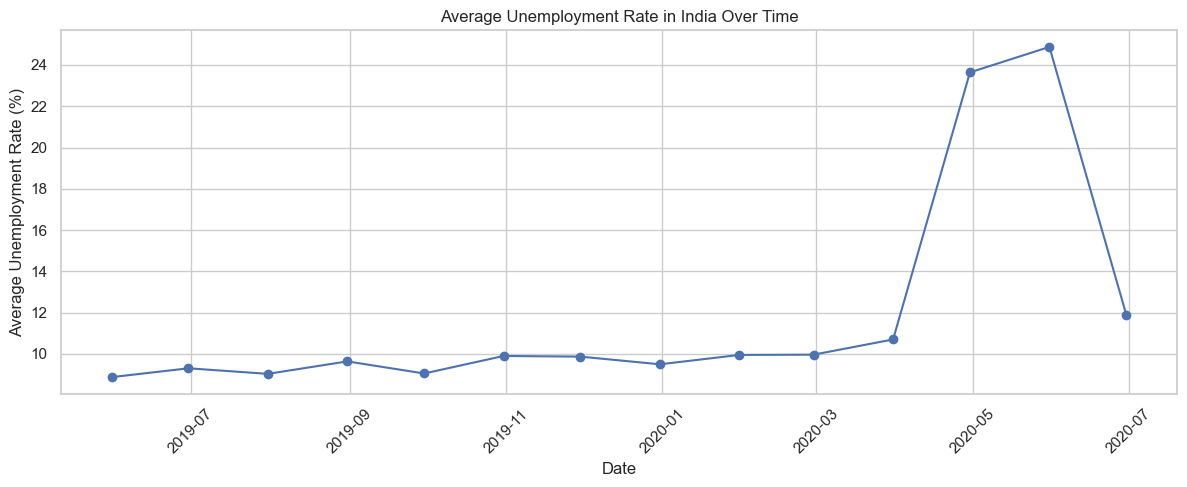

In [11]:
monthly_average = (
    df.groupby("Date")[unemployment_col]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_average.index,
    monthly_average.values,
    marker="o"
)

plt.title("Average Unemployment Rate in India Over Time")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The line chart shows how the average unemployment rate changed over time. I examined the peaks and declines to identify periods of unusual changes, particularly around the beginning of the COVID-19 pandemic in 2020.

Selected states: ['Delhi', 'Kerala', 'West Bengal']


C:\Users\dell\anaconda\anaconda.rr\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda\anaconda.rr\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda\anaconda.rr\Lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\dell\anaconda\anaconda.rr\Lib\site-packages\seaborn\relational.py:441: FutureWarning: DataFrameGroupBy.apply operate

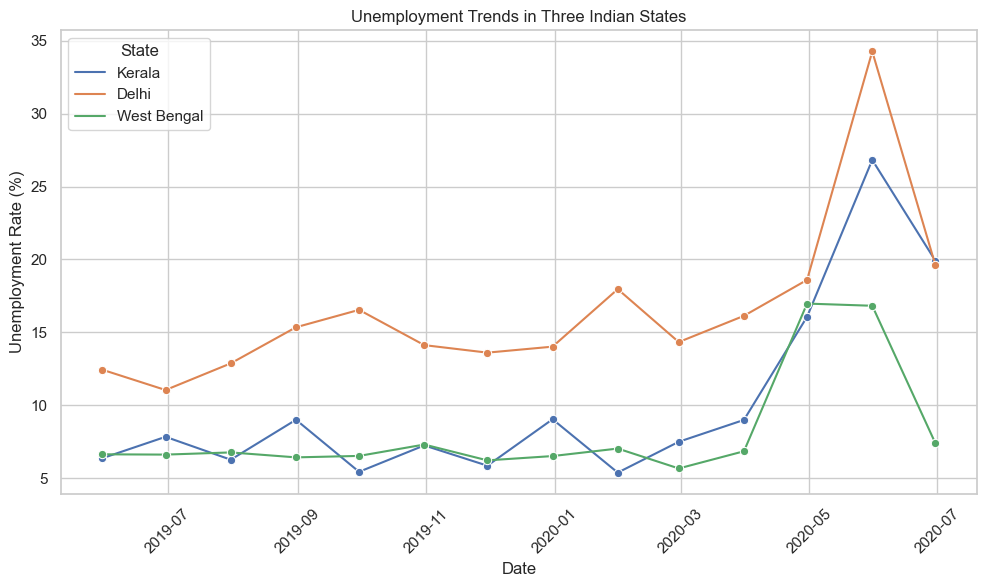

In [12]:
# Select three states if available in the dataset
preferred_states = [
    "Delhi",
    "Kerala",
    "West Bengal"
]

available_regions = df["Region"].dropna().unique()

selected_states = [
    state for state in preferred_states
    if state in available_regions
]

# If any preferred state is unavailable, use other regions
for region in available_regions:
    if len(selected_states) >= 3:
        break
    if region not in selected_states:
        selected_states.append(region)

selected_states = selected_states[:3]

print("Selected states:", selected_states)

state_data = df[df["Region"].isin(selected_states)]

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=state_data,
    x="Date",
    y=unemployment_col,
    hue="Region",
    marker="o",
    errorbar=None
)

plt.title("Unemployment Trends in Three Indian States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="State")
plt.tight_layout()
plt.show()

The chart compares unemployment trends across three Indian states.
delhi had a higher unemployment rate than kelara and west bengal throughout most of the observed period. kelara showed fluctuations in its unemployment rate, with a sharp increase around may-june 2020. west bengal mentained a relatively stable unemployment rate before experiencing a noticeable increase around may 2020.
all three states experienced a significant rise in unemployment around may 2020, which may be associated with the economic impact of the COVID-19.

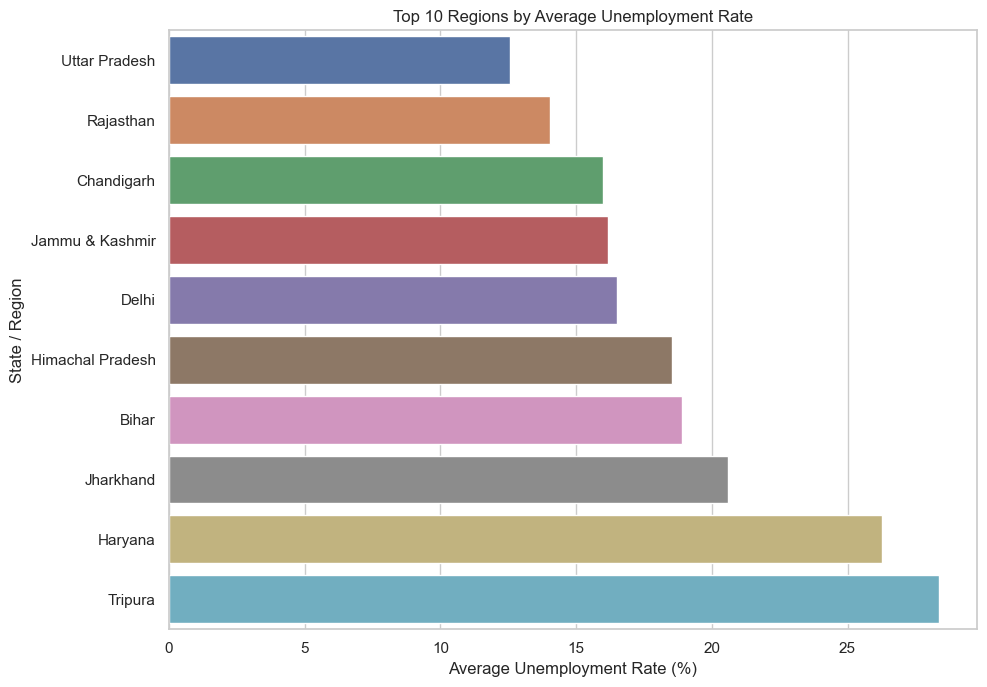

In [13]:
top10 = region_average.head(10).sort_values(ascending=True)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=top10.values,
    y=top10.index
)

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State / Region")
plt.tight_layout()
plt.show()

The bar chart ranks the ten regions with the highest average unemployment rates in the dataset. I identified the highest-ranked regions and compared the differences between their average rates.
States such as Tripura, Haryana, Jharkhand, and Bihar consistently recorded the highest average unemployment

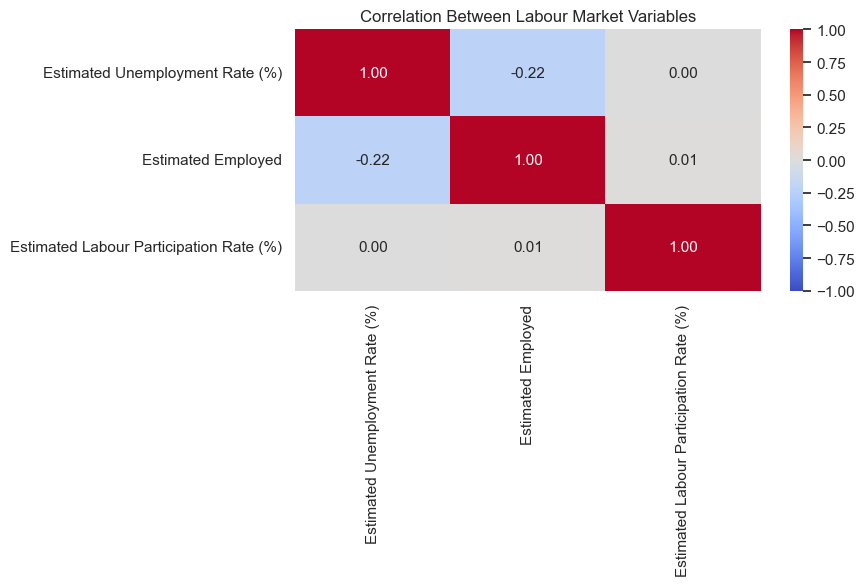

In [14]:
heatmap_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = df[heatmap_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Labour Market Variables")
plt.tight_layout()
plt.show()

The heatmap shows the pairwise correlations among estimated unemployment rate, estimated employment count and estimated labour participation rate. I interpreted the direction and strength of the correlations while remembering that correlation does not imply causation.

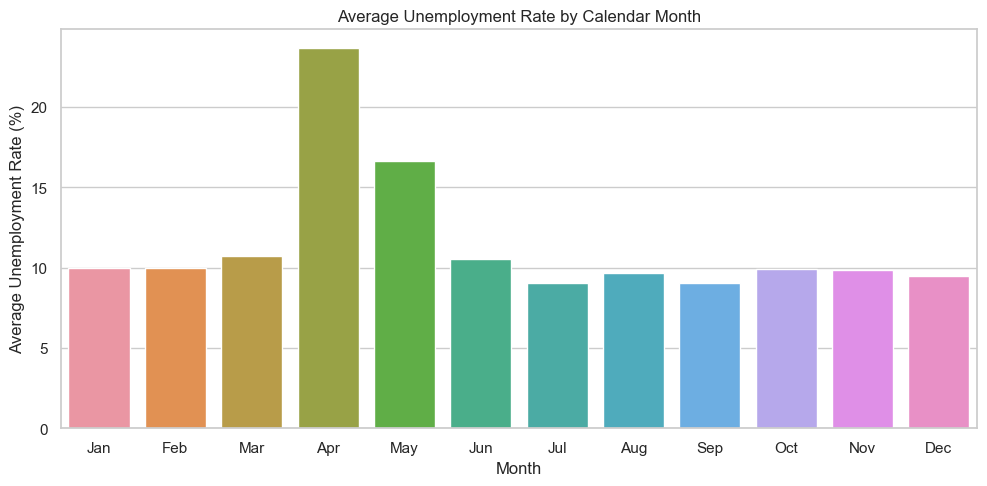

In [15]:
df["Month"] = df["Date"].dt.month

month_avg = (
    df.groupby("Month")[unemployment_col]
    .mean()
)

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

month_avg.index = month_avg.index.map(month_names)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_avg.index,
    y=month_avg.values
)

plt.title("Average Unemployment Rate by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

the graph shows a substatial increase in average unemployment during april & may (2020) followed by lower averages in subsequent months. this pattern in consistent with the disruption to employment during the early COVID-19 period. however, because the graph groups data by calender month across the available years, it does not necessarily represent changes in a single year only.

In [16]:
covid_start = pd.Timestamp("2020-03-01")

df["COVID Period"] = np.where(
    df["Date"] < covid_start,
    "Pre-COVID",
    "COVID period"
)

covid_summary = (
    df.groupby("COVID Period")[
        [
            "Estimated Unemployment Rate (%)",
            "Estimated Employed",
            "Estimated Labour Participation Rate (%)"
        ]
    ]
    .mean()
)

display(covid_summary)

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
COVID Period,,,
COVID period,17.774363,6.517203e+06,39.330049
Pre-COVID,9.509534,7.466028e+06,43.886119


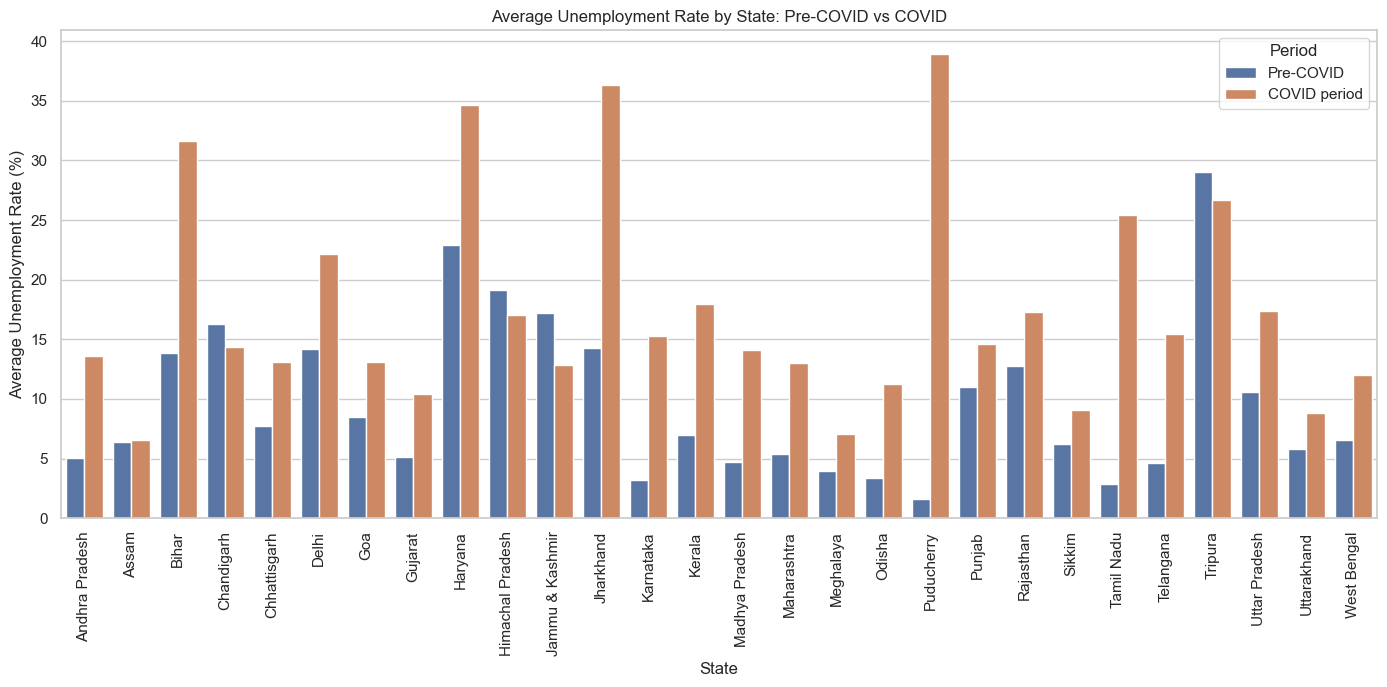

In [17]:
# Calculate the average unemployment rate for each state
# before and during the COVID-19 period

state_covid_avg = df.groupby(
    ["Region", "COVID Period"]
)[unemployment_col].mean().reset_index()

plt.figure(figsize=(14, 7))

sns.barplot(
    data=state_covid_avg,
    x="Region",
    y=unemployment_col,
    hue="COVID Period",
    hue_order=["Pre-COVID", "COVID period"],
    errorbar=None
)

plt.title("Average Unemployment Rate by State: Pre-COVID vs COVID")
plt.xlabel("State")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.legend(title="Period")
plt.tight_layout()
plt.show()

the graph suggests that the COVID-19 period was associated with higher average unemployment rates in most indian states, although the magnitude and direction of change differed by state.